# 📝 Foundations Quiz

This is a **hands-on, practical** quiz covering the Foundations notebooks (01–08). You'll write and run real code in the blank cells below, not just answer multiple choice. (For a quick conceptual self-check instead, see `quiz.md` in this folder.)

Answer each question in the provided cell. Some questions need code, others need a short written answer.

**Before you submit:**
1. **Restart & Run All** (notebook 02). Every cell must run top to bottom without errors. Run All stops at the first error, so a single broken cell hides every answer after it.
2. Upload this notebook **and** the `Quiz-OutputFiles` folder it creates.

## Setup
Run this first. Every file the quiz asks you to create goes into `OUT`.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUT = Path('Quiz-OutputFiles')
OUT.mkdir(exist_ok=True)

## Q1. Magic Commands (01)
Define three variables of different types. Then use a magic command to list them along with their types, and use a `!` shell command to capture the list of files in the current folder into a variable. Print how many files there are.

In [2]:
course = 'CMPS 3063'
credits = 3
gpa = 3.8
%whos

files = !dir /b
print(len(files), 'files in the current folder')

Variable   Type           Data/Info
-----------------------------------
OUT        WindowsPath    Quiz-OutputFiles
Path       type           <class 'pathlib._local.Path'>
course     str            CMPS 3063
credits    int            3
gpa        float          3.8
json       module         <module 'json' from 'C:\\<...>\Lib\\json\\__init__.py'>
np         module         <module 'numpy' from 'c:\<...>ges\\numpy\\__init__.py'>
pd         module         <module 'pandas' from 'c:<...>es\\pandas\\__init__.py'>
plt        module         <module 'matplotlib.pyplo<...>\\matplotlib\\pyplot.py'>
19 files in the current folder


In one sentence: what does `%whos` show that `%who` doesn't?

*Your Answer:* whos will show the variable type and who will just show the list

## Q2. Jupyter Workflow (02)
The three cells below only work if you run them out of order. **Reorder them** (don't change their code) so they run correctly from top to bottom.

In [3]:
price, quantity = 4.50, 3

In [4]:
total = price * quantity

In [5]:
print(f'Total cost: ${total:.2f}')

Total cost: $13.50


What do the execution-count numbers (like `[5]`) next to code cells tell you, and why can a notebook that works on your screen still fail for someone else?

*Your Answer:* The execution count numbers show the order that each cell is ran. The notbook can fail for someone else as the necessary code my not in before its results are used. 

In Command mode, which keyboard shortcut **deletes** a cell, and which one inserts a new cell **above**?

*Your Answer:* d d deletes a cell and A inserts a cell above.

## Q3. Getting Help (03)
1. Use `?` to display the documentation for `round`. (Put any comment on its own line: `round?  # comment` is a `SyntaxError`.)
2. Using what the docs say about `round`'s second argument, round `3.14159` to 2 decimal places.

In [6]:
round?

Signature: round(number, ndigits=None)
Docstring:
Round a number to a given precision in decimal digits.

The return value is an integer if ndigits is omitted or None.
Otherwise the return value has the same type as the number.  ndigits
may be negative.
Type:      builtin_function_or_method

In [7]:
print(round(3.14159, 2))


3.14


The code below raises an error. Run it, read the traceback from the bottom up, and then:
- In the Markdown cell after it, name the error type and explain what it means.
- In the code cell after that, fix it so it prints `Score: 5`.
- Finally, **comment out** the broken `print` line (select it and press `Ctrl+/`, or `Cmd+/` on Mac). Run All stops at the first error, so the error cell would otherwise keep your later answers from running.

In [8]:
score = 5
##print('Score: ' + score)

*Your Answer:* TypeError: can only concatenate str (not "int") to str, The + operator can only join a string to another string, and score is an integer

In [9]:
score = 5
print('Score: ' + str(score))

Score: 5


## Q4. Markdown (04)
Double-click the cell below and replace it with a Markdown cell containing:
- a heading `## My Hobbies`
- a bullet list of at least 3 hobbies
- a sentence containing a price, like *"my favorite hobby costs \$20 a month"*, that renders correctly (no accidental math!)
- the sample mean formula $\bar{x} = \frac{1}{n} \sum_{i=1}^{n} x_i$ written as **block** LaTeX

## My Hobbies
- 3D printing
- Gaming
- Robotics

My favorite hobby costs \$20 a month.

$$
\bar{x} = \frac{1}{n} \sum_{i=1}^{n} x_i
$$

## Q5. Files and Paths (05)
Use `pathlib` and `with open(..., encoding='utf-8')`:
1. Write `Hello World` to `OUT / 'hello.txt'`.
2. **Append** a second line, `Goodbye World`, without erasing the first.
3. Read the whole file back and print it.
4. Print the file's `.name`, `.suffix`, and whether it `.exists()`.

In [10]:
hello = OUT / 'hello.txt'

with open(hello, 'w', encoding='utf-8') as f:
    f.write('Hello World\n')

with open(hello, 'a', encoding='utf-8') as f:
    f.write('Goodbye World\n')

with open(hello, 'r', encoding='utf-8') as f:
    print(f.read())

print('name:  ', hello.name)
print('suffix:', hello.suffix)
print('exists:', hello.exists())

Hello World
Goodbye World

name:   hello.txt
suffix: .txt
exists: True


## Q6. JSON (05)
Create a dictionary describing a course (name, number of credits, and a **list** of topics). Save it to `OUT / 'course.json'` with `indent=2`, read it back into a new variable, and print whether the two dictionaries are equal (`==`).

In [11]:
course_info = {
    'name': 'Programming for Data Science',
    'credits': 3,
    'topics': ['Magic commands', 'Files and paths', 'Pandas I/O', 'Plotting', 'Timing'],
}

with open(OUT / 'course.json', 'w', encoding='utf-8') as f:
    json.dump(course_info, f, indent=2)

with open(OUT / 'course.json', 'r', encoding='utf-8') as f:
    course_loaded = json.load(f)

print('Equal:', course_loaded == course_info)

Equal: True


## Q7. Data I/O with Pandas (06)
1. Create a small DataFrame (3–5 rows, your own data, at least one number column) and save it to `OUT / 'my_data.csv'` **without** the index.
2. Read it back with Pandas, and show the first rows with `.head()` and the summary statistics with `.describe()`.
3. Convert it to JSON at `OUT / 'my_data.json'` using `orient='records'`, and print the file's text.

In [12]:
my_df = pd.DataFrame({
    'Course': ['Circuits II', 'Signals and Systems', 'Electronics I', 'Data Science'],
    'Credits': [3, 3, 4, 3],
    'Score': [92, 88, 95, 90],
})
my_df.to_csv(OUT / 'my_data.csv', index=False)

loaded = pd.read_csv(OUT / 'my_data.csv')
loaded.head()

,Course,Credits,Score
0,Circuits II,3,92
1,Signals and Systems,3,88
2,Electronics I,4,95
3,Data Science,3,90


In [13]:
loaded.describe()

,Credits,Score
count,4.00,4.000000
mean,3.25,91.250000
std,0.50,2.986079
min,3.00,88.000000
25%,3.00,89.500000
50%,3.00,91.000000
75%,3.25,92.750000
max,4.00,95.000000


In [14]:
loaded.to_json(OUT / 'my_data.json', orient='records', indent=2)
print((OUT / 'my_data.json').read_text(encoding='utf-8'))

[
  {
    "Course":"Circuits II",
    "Credits":3,
    "Score":92
  },
  {
    "Course":"Signals and Systems",
    "Credits":3,
    "Score":88
  },
  {
    "Course":"Electronics I",
    "Credits":4,
    "Score":95
  },
  {
    "Course":"Data Science",
    "Credits":3,
    "Score":90
  }
]


## Q8. Plotting (07)
Create a line plot of $y = x^2$ for 50 evenly spaced $x$ values from 0 to 10 (use NumPy). Give it a title and axis labels, and save it to `OUT / 'squares.png'` **before** you show it.

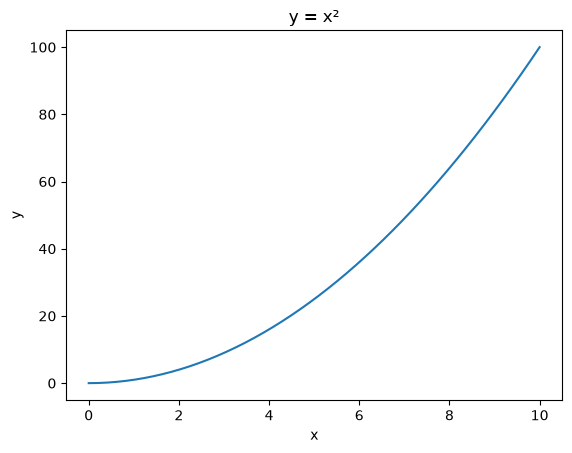

In [15]:
x = np.linspace(0, 10, 50)
y = x ** 2

plt.plot(x, y)
plt.title('y = x²')
plt.xlabel('x')
plt.ylabel('y')
plt.savefig(OUT / 'squares.png', dpi=150, bbox_inches='tight')
plt.show()


## Q9. Choosing and Building a Chart (07)
Generate 200 exam scores with `np.random.seed(1)` and `np.random.normal(70, 12, size=200)`. Pick the **best chart** for showing their distribution, and draw it with a title, axis labels, and a dashed vertical line marking the mean (with a legend).

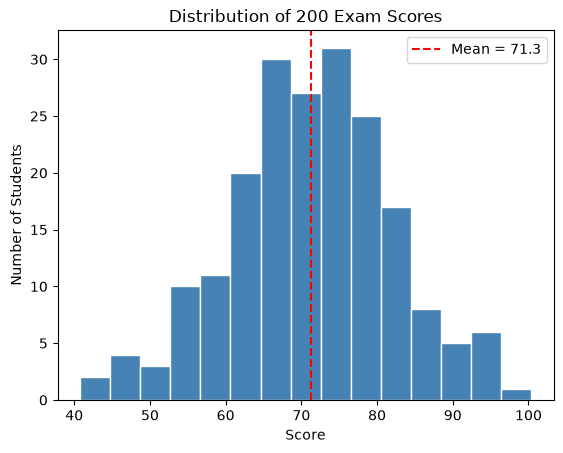

In [16]:
np.random.seed(1)
exam_scores = np.random.normal(70, 12, size=200)
mean_score = exam_scores.mean()

plt.hist(exam_scores, bins=15, color='steelblue', edgecolor='white')
plt.axvline(mean_score, color='red', linestyle='--', label=f'Mean = {mean_score:.1f}')
plt.title('Distribution of 200 Exam Scores')
plt.xlabel('Score')
plt.ylabel('Number of Students')
plt.legend()
plt.show()


In one or two sentences: why did you choose that chart type over a bar chart or a line plot?

*Your Answer:* It shows how the score cluster around the mean

## Q10. Timing (08)
Compare squaring one million numbers with a Python loop (or list comprehension) over a **list** and with NumPy on an **array**:
1. Create both inputs **before** timing, so the setup isn't measured.
2. Confirm that both approaches produce the same values.
3. Use `%timeit -o` for each, and print how many times faster NumPy is.

In [17]:
values_list = list(range(1_000_000))
values_array = np.arange(1_000_000)

loop_result = [v ** 2 for v in values_list]
numpy_result = values_array ** 2
print('Same values:', np.array_equal(np.array(loop_result), numpy_result))

t_loop = %timeit -o [v ** 2 for v in values_list]
t_numpy = %timeit -o values_array ** 2
print(f'NumPy is about {t_loop.average / t_numpy.average:.0f}x faster')

Same values: True
67.1 ms ± 3.58 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)
1.52 ms ± 45.1 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)
NumPy is about 44x faster


## Q11. Reflection
In 2–3 sentences each:
1. Why is it useful to mix Markdown and code in Jupyter notebooks?
2. Why should you Restart & Run All before submitting this quiz?

*Your Answer:* 1. Mixing markdown and notebook files can help with organization of the files so that the reader can follow along with the notbook flow without having to run any code.
2. Restarting and running will ensure that the notbook runs correctly in the order that it will be graded. With all of the values being reset, there is no chance of being out of order.

## 📦 Check Your Output Files
Run this last. You should see `hello.txt`, `course.json`, `my_data.csv`, `my_data.json`, and `squares.png`. Upload the `Quiz-OutputFiles` folder along with this notebook.

In [18]:
for path in sorted(OUT.rglob('*')):
    print(path)

Quiz-OutputFiles\course.json
Quiz-OutputFiles\hello.txt
Quiz-OutputFiles\my_data.csv
Quiz-OutputFiles\my_data.json
Quiz-OutputFiles\squares.png
